# Visualize Model Neurons

This notebook classifies neurons in models from Gornet and Thomson 2024 and Luo et al. 2024 such as the predictive coder and pretrained or randomized ResNet-18, ViT, etc. 

The second section runs the variance explained analysis on each of the neurons and returns scatter plots.

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

In [6]:
import numpy as np
a = np.array([1,2,3])
a.size

3

## Collect model activations

All models are shown observations from the same environment. The predictive coder is trained on views from smooth agent trajectories in this environment, and the rest of the models are either pretrained on ImageNet or randomized. 

(4913, 64, 64, 3)


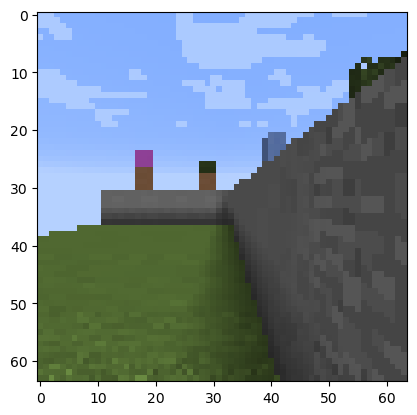

[120.5 197.5   0. ]


In [2]:
import numpy as np

model_name = 'resnet50' # predictive_coder | resnet50 | vit_b16 | resnet50_untrained | vgg16

# load in image observations and locations from the environment
obs_path = current_file_path / 'ann_datasets/data/small_world_r17_obs.npz'
coords_path = current_file_path / 'ann_datasets/data/small_world_r17_pos.npy'

obs = np.load(obs_path)['images']
coords = np.load(coords_path)

print(obs.shape)

# define unchanging args for the environment, previously was in config that I don't feel like messing with
N_ROTATIONS = 17
ENV_X_MIN = 120
ENV_X_MAX = 136
ENV_Y_MIN = 197
ENV_Y_MAX = 213

plt.imshow(obs[0])
plt.show()
print(coords[0])

In [3]:
coords[:10]

array([[120.5, 197.5,   0. ],
       [120.5, 197.5,  21. ],
       [120.5, 197.5,  42. ],
       [120.5, 197.5,  63. ],
       [120.5, 197.5,  84. ],
       [120.5, 197.5, 105. ],
       [120.5, 197.5, 126. ],
       [120.5, 197.5, 147. ],
       [120.5, 197.5, 168. ],
       [120.5, 197.5, 189. ]])

In [4]:
# predictive code latents are pre-prediction/post-encoding, or post-prediction/pre-decoding residual stream
# resnet can take layer1, layer3, layer4, or avgpool
# vit can take layer_{3, 6, 9, 12}
# vgg16 can take features.9, features.16, features.30, or classifier.3
# these are arbitrarily selected in Luo et al.

from ann_datasets.get_activations import load_model, get_activations

layer_name = 'avgpool'

config = {
    'model_name': model_name,
    'output_layer': layer_name,
    'env_bounds': [ENV_X_MIN, ENV_X_MAX, ENV_Y_MIN, ENV_Y_MAX],
    'n_rotations': N_ROTATIONS
}

model, preprocess = load_model(model_name, output_layer=layer_name)


/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
2025-08-22 09:10:28.763799: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-22 09:10:28.776491: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register fact

In [5]:
import numpy as np
import torch

device = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", device)

acts_path = get_activations(
    model, 
    preprocess, 
    obs, 
    model_name=model_name, 
    layer_name=layer_name, 
    device=device, 
    batch_size=17,
    dest_dir=f'model_activations/{model_name}_{layer_name}',
    #n_visits=10, # TODO implement
    #noise_coeff=0.1
)

acts_path


Device: cuda:0
[Saving activations] /home/mag/variance-analysis/ann_datasets/model_activations/resnet50_avgpool
(4913, 64, 64, 3)
Finished processing model activations.


[]

In [30]:
acts_path = ['/home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_post_pred_visits/acts.npz']

In [31]:
from pathlib import Path
from ann_datasets.classify_neurons import score_neurons, classify_neurons

neuron_scores_fpath, sampled_path = score_neurons(
    acts_path, 
    config, 
    sample_partial=False, 
    pixel_min_threshold=40, 
    use_old_place_method=False,
    n_visits=10
)

neuron_scores_fpath, sampled_path


[Check] transformer-based model detected, relu model_reps.


Charting neurons:   0%|          | 0/8192 [00:00<?, ?neuron/s]

/home/mag/variance-analysis/ann_datasets/score_utils.py:44: RuntimeWarning:

invalid value encountered in scalar divide



[Saved] /home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_post_pred/neuron_chart.npy


(PosixPath('/home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_post_pred/neuron_chart.npy'),
 None)

In [32]:
neuron_score_charts = np.load(neuron_scores_fpath, allow_pickle=True)
#sampled_neuron_idxs = np.load(sampled_path)

classifications = classify_neurons(neuron_score_charts)

classifications.keys()

dict_keys(['dead_neurons_indices', 'place_border_direction_cells_indices', 'place_and_border_not_direction_cells_indices', 'place_and_direction_not_border_cells_indices', 'border_and_direction_not_place_cells_indices', 'exclusive_place_cells_indices', 'exclusive_border_cells_indices', 'exclusive_direction_cells_indices', 'active_no_type_indices'])

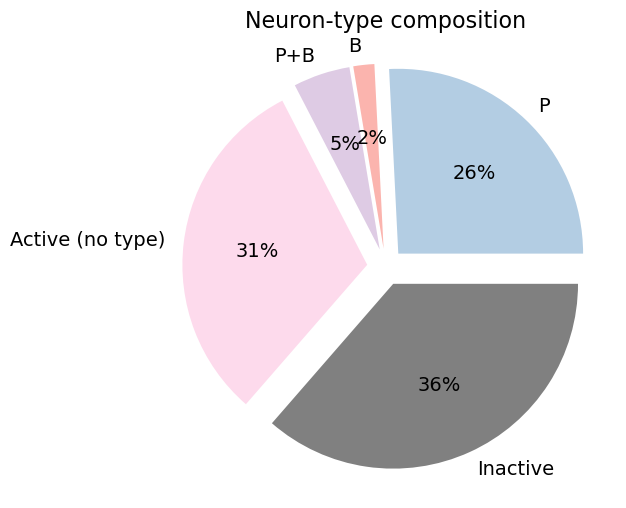

In [33]:
from ann_datasets.fig import plot_cell_type_pie

fig = plot_cell_type_pie(classifications)
plt.show()

In [5]:
# lets plot some neurons

acts_path = ['/home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_post_pred_visits/acts.npz']

activations = np.load(acts_path[0])['activations']

if 'vit' in model_name or 'post_pred' in layer_name:
    activations[activations < 0] = 0.

W = ENV_X_MAX - ENV_X_MIN + 1
H = ENV_Y_MAX - ENV_Y_MIN + 1
activations = activations.reshape(17*17*17, n_visits, -1)
activations = activations.reshape(17, 17, 17, n_visits, -1)
#activations.shape # (17, 17, 17, 1, 8192)
activations = np.moveaxis(activations, -1, 0)

In [6]:
activations.shape

(8192, 17, 17, 17, 10)

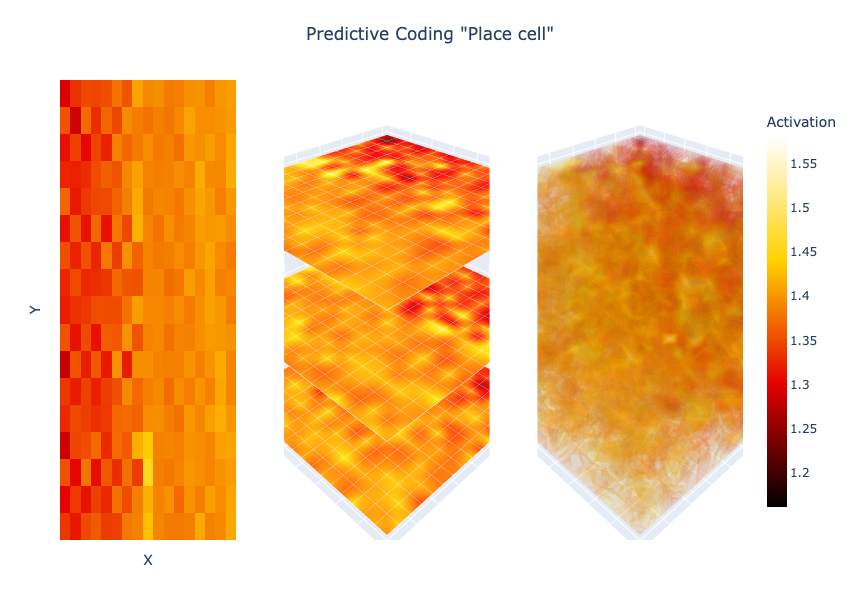

In [7]:
from ann_datasets.fig import plot_neuron_2d_3d

fig = plot_neuron_2d_3d(
    activations.mean(axis=4),
    neuron_idx=3,#classifications['exclusive_place_cells_indices'][20],
    axes_names=("X", "Y", "HD (°)"),
    n_slices=3,              # or slice_indices=[0,4,8,12]
    z_spacing=1.0,           # spreads the stack
    surf_opacity=1.0,
    grid_color="white",
    grid_width=1,
    z_label_degrees=True,
    overall_title="Predictive Coding \"Place cell\"",
)
fig.show()


# Variance Explained Analysis

Now let's see how much variance can be attributed to each of the possible stimulus dimensions for each neuron.

In [21]:
import numpy as np

device = 'cuda:0'

# --- config ---
n_visits   = 10
noise_frac = .1        # noise = noise_frac * (per-image, per-channel std)
seed       = 0           # for reproducibility
eps        = 1e-8        # to avoid zero std

n_locs, h, w, c = obs.shape
rng = np.random.default_rng(seed)

if np.issubdtype(obs.dtype, np.integer):
    obs_f = obs.astype(np.float32) / 255.0
else:
    obs_f = obs.astype(np.float32)

per_img_ch_std = obs_f.std(axis=(1, 2), keepdims=True) + eps   # (n_locs, 1, 1, c)

noise = rng.normal(loc=0.0, scale=1.0, size=(n_locs, n_visits, h, w, c)).astype(np.float32)

noise *= (noise_frac * per_img_ch_std[:, np.newaxis, ...])  # broadcast over visits

noisy_obs = obs_f[:, np.newaxis, ...] + noise               # (n_locs, n_visits, h, w, c)
noisy_obs = np.clip(noisy_obs, 0.0, 1.0)

noisy_obs = noisy_obs.reshape(n_locs * n_visits, h, w, c) # maybe it's getting reshaped incorrectly?

# 8) If your preprocess expects uint8 images, convert back to uint8.
#    Otherwise keep float32; most torchvision pipelines expect float in [0,1] (or normalized).
# noisy_obs_uint8 = (noisy_obs * 255.0).round().astype(np.uint8) # doesn't seem to do much

# --- get activations as before ---

noisy_acts_path = get_activations(
    model,
    preprocess, 
    noisy_obs,                 # or noisy_obs_uint8, depending on your pipeline
    model_name=model_name, 
    layer_name=layer_name, 
    device=device, 
    batch_size=17,
    dest_dir=f'model_activations/{model_name}_{layer_name}_visits'
)

'''
raw_visits = np.load(noisy_acts_path[0])['activations']
raw_visits = raw_visits.reshape(N_ROTATIONS * N_ROTATIONS, N_ROTATIONS, n_visits, -1)
raw_visits.shape
'''

[Saving activations] /home/mag/variance-analysis/ann_datasets/model_activations/resnet50_avgpool_visits
Finished processing model activations.


"\nraw_visits = np.load(noisy_acts_path[0])['activations']\nraw_visits = raw_visits.reshape(N_ROTATIONS * N_ROTATIONS, N_ROTATIONS, n_visits, -1)\nraw_visits.shape\n"

In [20]:
!ls /home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_post_pred_visits

acts.npz


In [15]:
n_visits = 10
raw_visits = np.load(f'/home/mag/variance-analysis/ann_datasets/model_activations/{model_name}_{layer_name}_visits/acts.npz')['activations']
raw_visits = raw_visits.reshape(17*17*17, n_visits, -1)
raw_visits = raw_visits.reshape(17, 17, 17, n_visits, -1)
raw_visits = raw_visits.reshape(17*17, 17, n_visits, -1)
_, _, _, n_neurons = raw_visits.shape

FileNotFoundError: [Errno 2] No such file or directory: '/home/mag/variance-analysis/ann_datasets/model_activations/resnet50_avgpool_visits/acts.npz'

In [12]:
n_neurons

8192

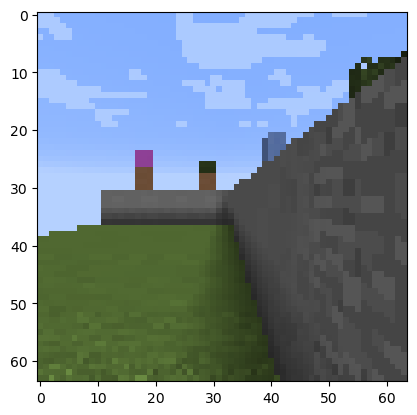

In [175]:
plt.imshow(obs[0])
plt.show()

In [35]:
from numba import njit, prange
import numpy as np

@njit(parallel=True, fastmath=True)
def get_splits_numba(visits, min_visits=2, cap=False, seed=0):
    np.random.seed(seed)

    s1_bins, s2_bins, n_max_visits, n_neurons = visits.shape
    total_mean = np.full((s1_bins, s2_bins, n_neurons), np.nan)
    train_mean = total_mean.copy()
    test_mean  = total_mean.copy()
    train_occ  = np.zeros((s1_bins, s2_bins))
    test_occ   = np.zeros((s1_bins, s2_bins))

    for s1 in prange(s1_bins):
        for s2 in range(s2_bins):
            for n in range(n_neurons):

                valid = np.where(~np.isnan(visits[s1, s2, :, n]))[0]
                cnt   = valid.size
                if cnt < min_visits:
                    continue                       

                take_n = min_visits if cap else cnt
                perm   = np.random.permutation(cnt)[:take_n]
                idx    = valid[perm]

                half   = take_n // 2
                tr_idx = idx[:half]
                te_idx = idx[half:]

                train_vals = visits[s1, s2, tr_idx, n]
                test_vals  = visits[s1, s2, te_idx, n]

                train_mean[s1, s2, n] = train_vals.mean()
                test_mean [s1, s2, n] = test_vals.mean()
                total_mean[s1, s2, n] = visits[s1, s2, idx, n].mean()

            train_occ[s1, s2] = tr_idx.size
            test_occ [s1, s2] = te_idx.size

    return total_mean, train_mean, test_mean, train_occ, test_occ

In [83]:
#from src.methods import get_splits, quantify_variance

#raw_visits_place_cells = raw_visits[:, :, :, classifications['exclusive_place_cells_indices']]

total_mean, train_mean, test_mean, train_occ, test_occ = get_splits_numba(raw_visits, seed=413)
print(train_mean.shape) # this is x*y, hd, neurons raw visits binned map
s1_bins, s2_bins, n_neurons = train_mean.shape

# it's possible that in the reshape, we're accidentally keeping the hd dimension instead of the x or y

# let's try doing this with x and y first
#train_mean = np.mean(train_mean, axis=1).reshape(17, 17, n_neurons)
#test_mean = np.mean(test_mean, axis=1).reshape(17, 17, n_neurons)

# I think this should be y and hd then
train_mean = np.mean(train_mean.reshape(17, 17, 17, n_neurons), axis=0) # is this ok then?
test_mean = np.mean(test_mean.reshape(17, 17, 17, n_neurons), axis=0)


(289, 17, 8192)


In [36]:
from tqdm import tqdm
from src.methods import quantify_variance

n_splits = 1

s1_var = np.zeros((n_splits, n_neurons))
s2_var = np.zeros((n_splits, n_neurons))
rate_maps = np.zeros((N_ROTATIONS * N_ROTATIONS, N_ROTATIONS, n_neurons, n_splits))

n_visits = 10
noise_std = 0.01

for s in tqdm(range(n_splits)):
    np.random.seed(s)
    #acts_path = f'/home/mag/variance-analysis/ann_datasets/model_activations/{model_name}_{layer_name}_visits_seed_{s}/acts.npz'
    #raw_visits = np.load(acts_path)['activations']
    #raw_visits = raw_visits.reshape(N_ROTATIONS * N_ROTATIONS, N_ROTATIONS, n_visits, -1)
    total_mean, train_mean, test_mean, train_occ, test_occ = get_splits_numba(raw_visits, seed=s)
    rate_maps[:, :, :, s] = total_mean # n_r, n_r, n_neurons
    
    for n in range(n_neurons):
        s1_var[s, n] = quantify_variance(train_mean[:, :, n], test_mean[:, :, n], axis=0)[0]
        s2_var[s, n] = quantify_variance(train_mean[:, :, n], test_mean[:, :, n], axis=1)[0]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:16<00:00, 16.79s/it]


In [37]:
place_cells = np.asarray(classifications['exclusive_place_cells_indices'])
is_place = np.isin(np.arange(n_neurons), place_cells)

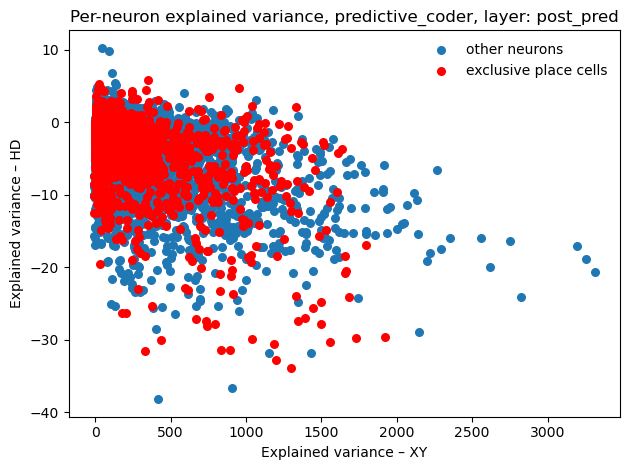

In [38]:
split_index = 0

plt.scatter(
    s1_var[split_index][~is_place],
    s2_var[split_index][~is_place],
    s=30,
    label="other neurons"
)

# Overlay place cells in red
plt.scatter(
    s1_var[split_index][is_place],
    s2_var[split_index][is_place],
    color="red",
    s=30,
    label="exclusive place cells"
)

#plt.xlim(-0.00000, 0.00003)
#plt.ylim(-0.00003, 0.00003)

plt.xlabel("Explained variance – XY")
plt.ylabel("Explained variance – HD")
plt.title(f"Per-neuron explained variance, {model_name}, layer: {layer_name}")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


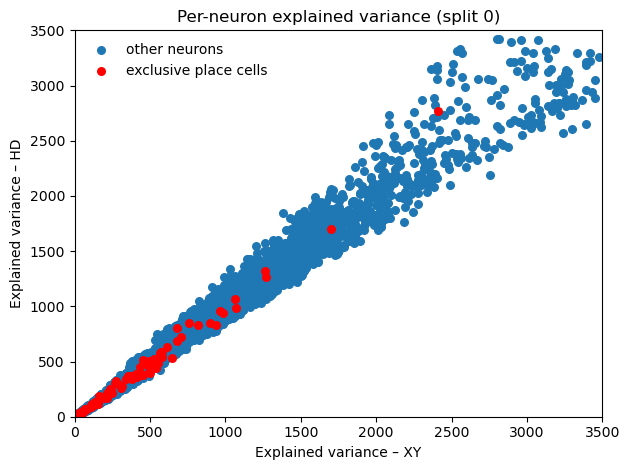

In [18]:
split_index = 0

plt.scatter(
    s1_var[split_index][~is_place],
    s2_var[split_index][~is_place],
    s=30,
    label="other neurons"
)

# Overlay place cells in red
plt.scatter(
    s1_var[split_index][is_place],
    s2_var[split_index][is_place],
    color="red",
    s=30,
    label="exclusive place cells"
)

plt.xlim(0, 3500)
plt.ylim(0, 3500)

plt.xlabel("Explained variance – XY")
plt.ylabel("Explained variance – HD")
plt.title(f"Per-neuron explained variance (split {split_index})")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


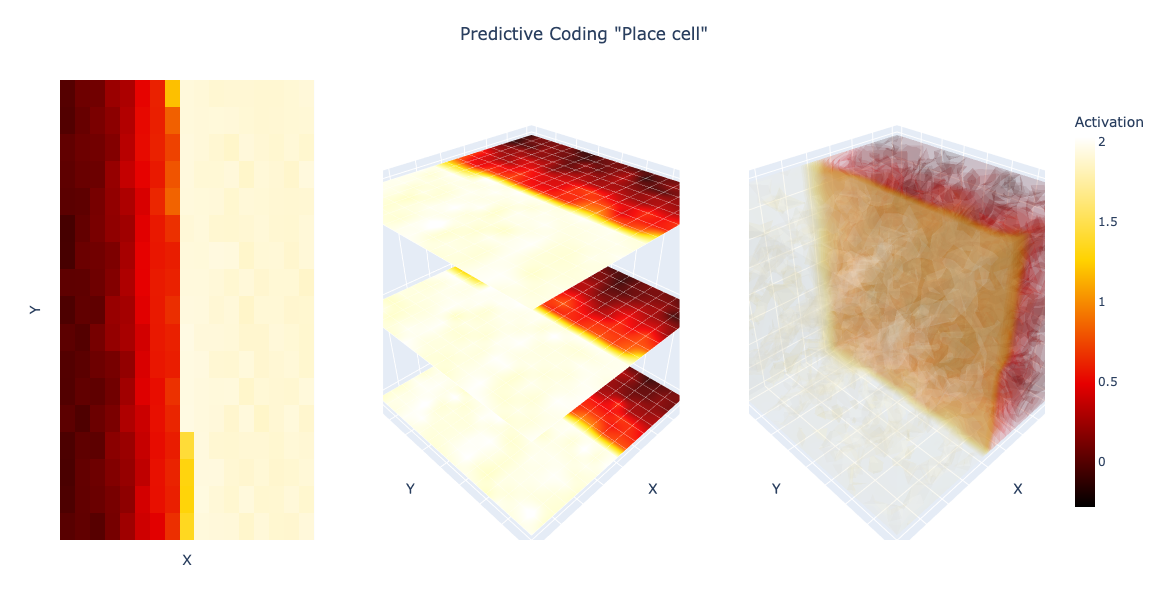

In [39]:
from ann_datasets.fig import plot_neuron_2d_3d
# now let's look at some of the top XY selective neurons to see if they really are that selective.

top_xy_var_idx = np.argmax(s1_var[0])
rate_map = rate_maps[:, :, :, 0].reshape(17, 17, 17, 8192)
rate_map = np.moveaxis(rate_map, -1, 0)

fig = plot_neuron_2d_3d(
    rate_map, # just look at the first random seed, this actually shouldn't matter at all for total rate maps since the seed determines the fold split
    neuron_idx=top_xy_var_idx, #classifications['exclusive_place_cells_indices'][20],
    axes_names=("X", "Y", "HD (°)"),
    n_slices=3,              # or slice_indices=[0,4,8,12]
    z_spacing=1.0,           # spreads the stack
    surf_opacity=1.0,
    grid_color="white",
    grid_width=1,
    z_label_degrees=True,
    overall_title="Predictive Coding \"Place cell\"",
)
fig.show()
